# 02. 패치 효과 분석 (16.20 → 16.21 → 16.22)

협곡 기준 밸런스 패치가 일반 칼바람(큐 450) 승률을 실제로 얼마나 움직였는지 추정한다.

| 질문 | 방법 |
|---|---|
| 1. 챔피언별로 패치 효과가 있었나? | 챔피언별 이중차분(DiD), 경기 단위 군집 표준오차 |
| 2. 이 방법은 믿을 만한가? | 위약 검정: 바뀌지 않은 챔피언에 가짜 처치를 줘서 오탐률 확인 |
| 3. 버프·너프는 평균적으로 몇 %p로 나타나나? | 그룹별 메타분석 (랜덤 효과) |
| 4. 개별 추정치 중 믿을 만한 건? | 경험적 베이즈 축소 |
| 5. 칼바람 전용 보정이 필요한 챔피언은? | 승률 수준의 베이즈 축소 + 패치 간 일관성 |

모든 승률·효과에는 표본 수(n)와 95% 신뢰구간을 같이 표시한다.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from db import get_engine

# 비교 구간: 사후 패치 -> 사전 패치
TRANSITIONS = {"16.20": "16.19", "16.21": "16.20", "16.22": "16.21"}
# 사후 패치에서 바뀐 아이템 중 칼바람 구매가 많은 것 (Data Dragon ID)
CHANGED_ITEMS = {
    "16.20": {3073: "실험적 마공학판", 3152: "마법공학 로켓 벨트", 3085: "루난의 허리케인"},
    "16.21": {126697: "오만"},
    "16.22": {2501: "지배자의 피갑옷"},
}
EXPOSED_MIN_RATE, EXPOSED_MIN_N = 0.20, 30   # 사전 패치 구매율 20% 이상이면 아이템 노출군
DID_MIN_N = 30                               # 전후 각각 최소 경기 수
PLACEBO_MIN_N = 300                          # 위약 검정에 쓸 대조군 챔피언 최소 경기 수
EXTRA_PLACEBO = {"16.22": ["Shen"]}          # 칼바람과 무관한 변경만 있던 챔피언

COL = {"buff": "#2a78d6", "nerf": "#eb6834", "other": "#8a8985", "ink": "#3d3d3a"}
plt.rcParams.update({
    "font.family": "Apple SD Gothic Neo", "axes.unicode_minus": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8985", "axes.axisbelow": True, "figure.dpi": 110,
})
pd.set_option("display.max_rows", 80)
engine = get_engine()

## 1. 데이터

In [2]:
patches = sorted(set(TRANSITIONS) | set(TRANSITIONS.values()))
parts = pd.read_sql(
    f"""SELECT p.match_id, p.champion_name AS champ, p.win, m.patch,
              p.item0, p.item1, p.item2, p.item3, p.item4, p.item5, p.item6
       FROM participants p JOIN matches m USING (match_id)
       WHERE m.queue_id = 450 AND m.early_surrender = 0
         AND m.patch IN ({",".join(f"'{x}'" for x in patches)})""", engine)
changes = pd.read_csv(ROOT / "data/patch_changes/champion_changes.csv", dtype={"patch": str})
# 한글 이름: Data Dragon 공식 champion.json (ko_KR)에서 만든 표
names = pd.read_csv(ROOT / "data/processed/champion_names.csv")
ko = dict(zip(names.champion_name, names.champion_ko))
item_cols = [f"item{i}" for i in range(7)]

parts.groupby("patch").agg(matches=("match_id", "nunique"), rows=("win", "size"),
                           champions=("champ", "nunique"))

,matches,rows,champions
patch,,,
16.19,14538,145380,173
16.20,15888,158880,173
16.21,20878,208780,173
16.22,19868,198680,173


리메이크는 뺐다. 패치는 날짜가 아니라 `gameVersion` 기준이다.

## 2. 처치군·대조군 설계

구간마다 사후 패치의 패치노트로 그룹을 나눈다.

- **buff / nerf / adjust / rework**: 협곡 일반 밸런스 변경 (칼바람에도 적용)
- **item**: 직접 변경은 없지만, 바뀐 아이템을 사전 패치에서 20% 이상 산 챔피언. 간접 영향을 받으므로 대조군에서 뺀다
- **placebo**: 칼바람 승률에 영향이 없어야 하는 변경 (수치 변화 없는 버그 수정, 몬스터 전용 변경)
- **control**: 그 외 전부. 메타·계절 변화를 걷어내는 기준선

In [3]:
def exposed_champs(pre, items):
    d = parts[parts.patch == pre]
    rows = []
    for item_id, name in items.items():
        r = (d.assign(bought=d[item_cols].eq(item_id).any(axis=1))
               .groupby("champ").agg(n=("bought", "size"), rate=("bought", "mean")))
        r = r[(r.n >= EXPOSED_MIN_N) & (r.rate >= EXPOSED_MIN_RATE)]
        rows += [dict(item=name, champ=c, n=int(x.n), buy_rate=round(x.rate, 2)) for c, x in r.iterrows()]
    return pd.DataFrame(rows)


design = {}
for post, pre in TRANSITIONS.items():
    cp = changes[(changes.patch == post) & (changes.applies_to_aram == "yes")]
    rift = cp[cp.scope == "rift"]
    direction = dict(zip(rift.champion_name, rift.direction))
    changed = {c for c, d in direction.items() if d in ("buff", "nerf", "adjust", "rework")}
    aram = set(cp[cp.scope == "aram"].champion_name)   # 칼바람 전용 보정치 변경
    exp = exposed_champs(pre, CHANGED_ITEMS[post])
    item = set(exp.champ) - changed - aram
    placebo = {c for c, d in direction.items() if d == "fix"} | set(EXTRA_PLACEBO.get(post, []))
    group = ({c: direction[c] for c in changed} | {c: "item" for c in item}
             | {c: "placebo" for c in placebo} | {c: "aram" for c in aram})
    design[post] = dict(pre=pre, group=group, exposed=exp)
    counts = pd.Series(group).value_counts().to_dict()
    print(f"{pre} → {post}: {counts}")

exposure = pd.concat([cfg["exposed"].assign(구간=f"{cfg['pre']}→{post}") for post, cfg in design.items()])
exposure["직접변경"] = [design[t.split("→")[1]]["group"].get(c, "") for t, c in zip(exposure.구간, exposure.champ)]
exposure["직접변경"] = exposure.직접변경.replace("item", "")
exposure.pivot_table(index="item", columns="구간", values="champ", aggfunc="count").fillna(0).astype(int)

16.19 → 16.20: {'item': 13, 'buff': 10, 'nerf': 5, 'aram': 2, 'adjust': 1}
16.20 → 16.21: {'item': 12, 'buff': 11, 'nerf': 9, 'adjust': 3, 'placebo': 2}
16.21 → 16.22: {'buff': 9, 'nerf': 3, 'item': 2, 'placebo': 1, 'rework': 1}


구간,16.19→16.20,16.20→16.21,16.21→16.22
item,,,
루난의 허리케인,9,0,0
마법공학 로켓 벨트,7,0,0
실험적 마공학판,3,0,0
오만,0,15,0
지배자의 피갑옷,0,0,2


26.21에서 바뀐 **오만**은 칼바람에서 암살자·원딜이 많이 산다. 키아나·바루스·리 신은 직접 변경도 있어 처치군에 남기고,
나머지는 아이템 노출군으로 따로 추정한다. 오만은 근접 상향·원거리 하향이라 노출군 안에서도 방향이 갈린다.

## 3. 챔피언별 DiD

선형확률모형 `win ~ is_c * post`를 대상 챔피언 + 대조군 데이터에 맞추고, `is_c:post` 계수를 효과로 본다.
같은 경기의 10명은 서로 독립이 아니므로 표준오차는 경기 단위로 군집한다.

In [4]:
def did(d, champ):
    s = d[(d.champ == champ) | d.is_ctrl].assign(is_c=lambda x: (x.champ == champ).astype(int))
    fit = smf.ols("win ~ is_c * post", s).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(s.match_id)[0]})
    return fit.params["is_c:post"] * 100, fit.bse["is_c:post"] * 100


panel = {}   # 구간별 분석 데이터 (위약 검정에서 다시 씀)
rows = []
for post, cfg in design.items():
    pre, group = cfg["pre"], cfg["group"]
    d = parts[parts.patch.isin([pre, post])].copy()
    d["post"] = (d.patch == post).astype(int)
    d["is_ctrl"] = ~d.champ.isin([c for c, g in group.items() if g != "placebo"])
    n = d.groupby(["champ", "post"]).size().unstack(fill_value=0)
    panel[post] = (d, n)
    for champ, g in sorted(group.items()):
        if champ not in n.index or n.loc[champ].min() < DID_MIN_N:
            print(f"표본 부족으로 제외: {post} {champ}")
            continue
        # 위약 챔피언은 대조군에서 자기 자신을 빼고 추정
        dd = d.assign(is_ctrl=d.is_ctrl & (d.champ != champ))
        est, se = did(dd, champ)
        rows.append(dict(transition=f"{pre}→{post}", post=post, champ=champ, name=ko.get(champ, champ),
                         group=g, n_pre=n.loc[champ, 0], n_post=n.loc[champ, 1], est=est, se=se))

res = pd.DataFrame(rows)
res["lo"], res["hi"] = res.est - 1.96 * res.se, res.est + 1.96 * res.se
res["p"] = 2 * stats.norm.sf((res.est / res.se).abs())
res.round(2).sort_values(["transition", "est"])

,transition,post,champ,name,group,n_pre,n_post,est,se,lo,hi,p
4,16.19→16.20,16.20,Belveth,벨베스,aram,334,300,-7.80,3.97,-15.57,-0.02,0.05
30,16.19→16.20,16.20,Zeri,제리,item,769,826,-4.48,2.51,-9.39,0.44,0.07
29,16.19→16.20,16.20,Yunara,유나라,nerf,922,1243,-4.42,2.19,-8.70,-0.13,0.04
0,16.19→16.20,16.20,Akali,아칼리,item,646,754,-3.92,2.64,-9.09,1.24,0.14
13,16.19→16.20,16.20,KogMaw,코그모,item,1352,1506,-2.71,1.89,-6.42,1.00,0.15
...,...,...,...,...,...,...,...,...,...,...,...,...
76,16.21→16.22,16.22,Rumble,럼블,buff,1201,1119,1.66,2.09,-2.44,5.75,0.43
79,16.21→16.22,16.22,Smolder,스몰더,buff,1614,1558,1.83,1.78,-1.66,5.31,0.30
75,16.21→16.22,16.22,Naafiri,나피리,buff,520,495,3.04,3.10,-3.03,9.12,0.33
81,16.21→16.22,16.22,Viktor,빅토르,buff,1395,1535,3.12,1.85,-0.52,6.75,0.09


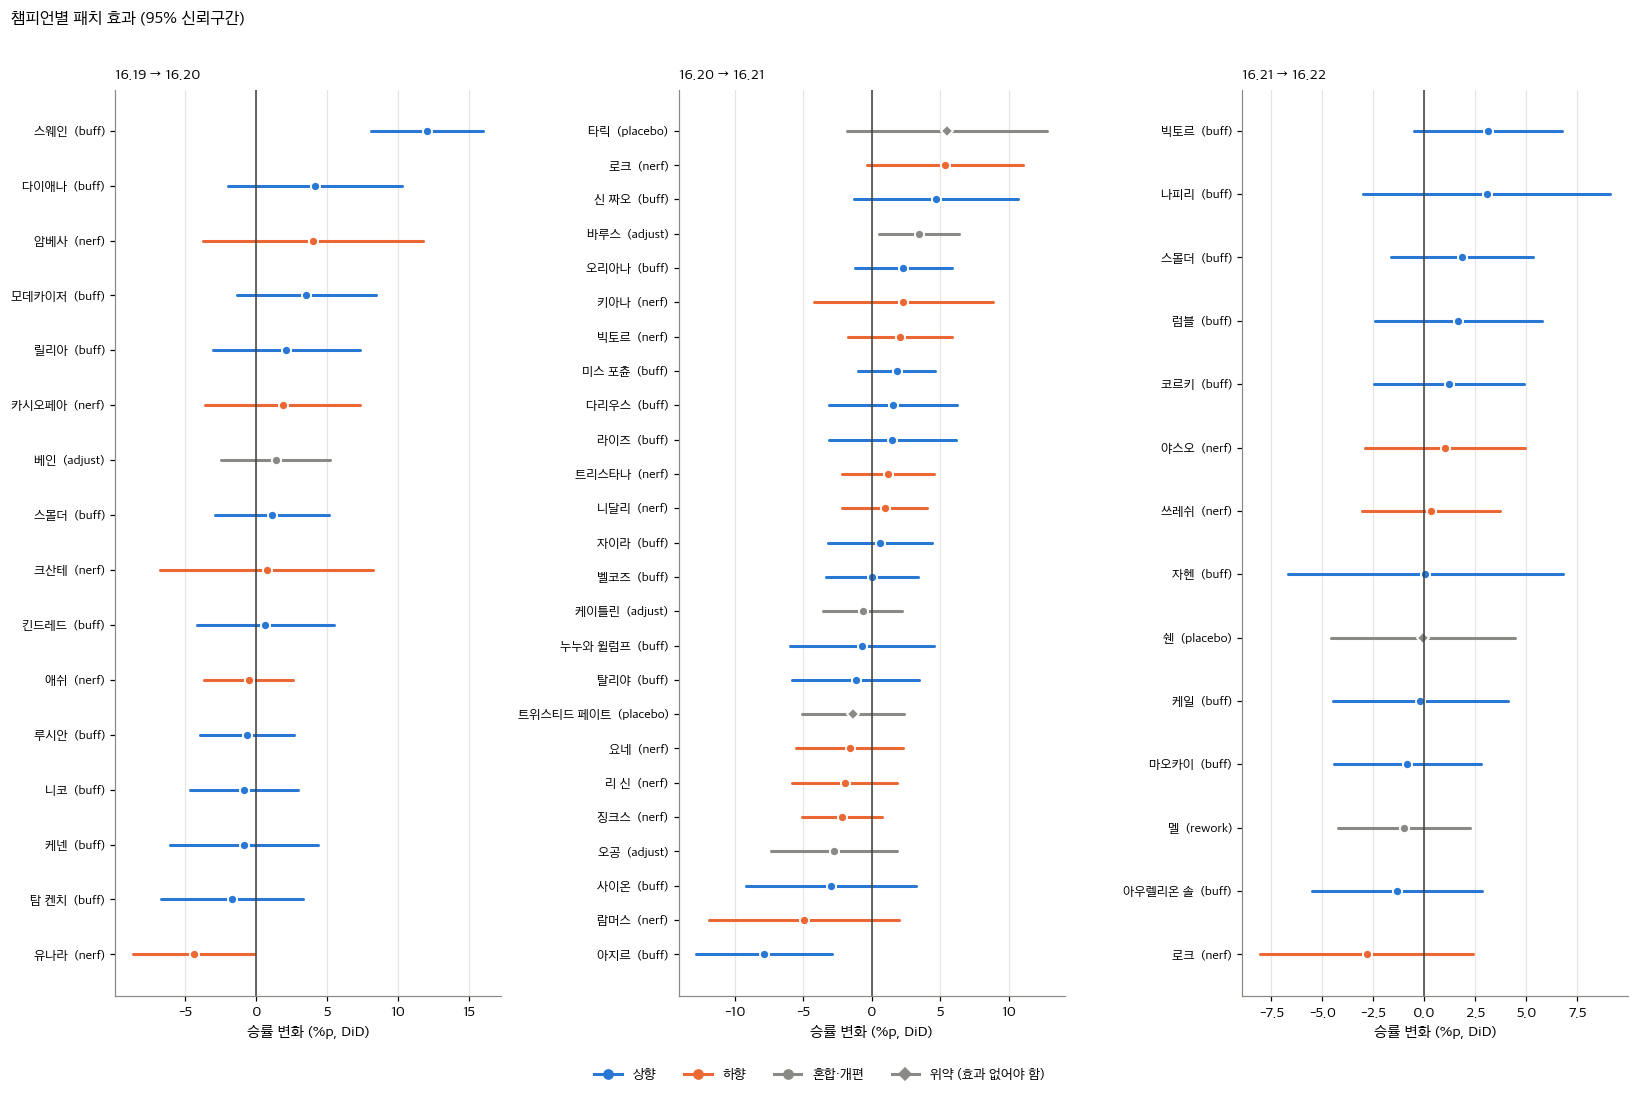

In [5]:
GCOL = {"buff": COL["buff"], "nerf": COL["nerf"]}
fig, axes = plt.subplots(1, len(TRANSITIONS), figsize=(15, 10))
for ax, (post, g) in zip(axes, res.groupby("post")):
    g = g[~g.group.isin(["item", "aram"])].sort_values("est")
    y = np.arange(len(g))
    for yi, r in zip(y, g.itertuples()):
        c = GCOL.get(r.group, COL["other"])
        ax.plot([r.lo, r.hi], [yi, yi], color=c, lw=2, solid_capstyle="round")
        ax.plot(r.est, yi, ls="", ms=6, color=c, mec="white", mew=1.2,
                marker="D" if r.group == "placebo" else "o")
    ax.axvline(0, color=COL["ink"], lw=1)
    ax.set_yticks(y, [f"{r.name}  ({r.group})" for r in g.itertuples()], fontsize=8.5)
    ax.set_xlabel("승률 변화 (%p, DiD)")
    ax.set_title(f"{design[post]['pre']} → {post}", loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], color=COL["buff"], marker="o", lw=2, label="상향"),
           plt.Line2D([], [], color=COL["nerf"], marker="o", lw=2, label="하향"),
           plt.Line2D([], [], color=COL["other"], marker="o", lw=2, label="혼합·개편"),
           plt.Line2D([], [], color=COL["other"], marker="D", lw=2, label="위약 (효과 없어야 함)")]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=9)
fig.suptitle("챔피언별 패치 효과 (95% 신뢰구간)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0.03, 1, 0.97))

In [6]:
sig = res[res.p < 0.05].sort_values("p")
print(f"p < 0.05: {len(sig)} / {len(res)}건 (우연만으로도 약 {len(res) * 0.05:.1f}건 기대)")
print(f"Bonferroni 기준 p < {0.05 / len(res):.4f}: {(res.p < 0.05 / len(res)).sum()}건")
sig[["transition", "name", "group", "n_pre", "n_post", "est", "lo", "hi", "p"]].round(3)

p < 0.05: 6 / 84건 (우연만으로도 약 4.2건 기대)
Bonferroni 기준 p < 0.0006: 1건


,transition,name,group,n_pre,n_post,est,lo,hi,p
23,16.19→16.20,스웨인,buff,1101,1364,12.088,8.133,16.043,0.000
31,16.20→16.21,아지르,buff,659,969,-7.865,-12.807,-2.923,0.002
61,16.20→16.21,바루스,adjust,2039,2641,3.437,0.508,6.366,0.021
29,16.19→16.20,유나라,nerf,922,1243,-4.418,-8.701,-0.135,0.043
57,16.20→16.21,탈론,item,480,569,6.253,0.184,12.322,0.043
4,16.19→16.20,벨베스,aram,334,300,-7.798,-15.572,-0.023,0.049


- **스웨인 (26.20 상향): +12%p.** 다중비교(Bonferroni) 보정 후에도 유일하게 유의하다. 칼바람 승률이 50% → 62%로 뛰었고,
  이후 두 패치 동안 64~65%를 유지했다. 협곡에서는 W(제국의 눈) 피해량·재사용 대기시간을 올린 중간 규모 상향이었지만,
  긴 사거리 광역 속박 스킬이 한 라인 한타에서 계속 쓰이는 칼바람에서는 효과가 크게 증폭된 것으로 보인다.
  **협곡 기준 변경이 칼바람에서 과하게 작동한 대표 사례다.**
- 아지르 (26.21 상향): 오히려 -8%p. 상향은 레벨당 마나 40→50뿐이라 패치로 설명하기 어렵다. Bonferroni 기준은 넘지 못한다.
- 바루스는 패치 도중(10/22) 추가 상향, 탈론은 오만 근접 상향의 수혜라 방향이 맞는다.
- 비교를 80번 넘게 하면 우연으로도 4건 정도는 p < 0.05가 나온다. 개별 결과는 위약 검정, 그룹 추정과 같이 봐야 한다.

## 4. 방법 검증: 위약 검정

패치에서 **바뀌지 않은** 챔피언 하나를 골라 가짜 처치군으로 놓고, 나머지 대조군과 DiD를 돌린다.
방법이 맞다면 효과가 없어야 하므로 z값이 표준정규분포를 따르고, |z| > 1.96은 약 5%만 나와야 한다.

In [7]:
plac = []
for post, (d, n) in panel.items():
    group = design[post]["group"]
    for champ in n.index:
        if champ in group or n.loc[champ].min() < PLACEBO_MIN_N:
            continue
        dd = d.assign(is_ctrl=d.is_ctrl & (d.champ != champ))
        est, se = did(dd, champ)
        plac.append(dict(post=post, champ=champ, est=est, se=se))
plac = pd.DataFrame(plac)
plac["z"] = plac.est / plac.se
false_pos = (plac.z.abs() > 1.96).mean()
print(f"대조군 챔피언 {len(plac)}건: |z| > 1.96 비율 {false_pos:.1%} (기대 5%), z 표준편차 {plac.z.std():.2f} (기대 1.00)")
plac.groupby("post").z.agg(n="size", sd="std", false_pos=lambda z: (z.abs() > 1.96).mean()).round(3)

대조군 챔피언 396건: |z| > 1.96 비율 6.3% (기대 5%), z 표준편차 1.06 (기대 1.00)


,n,sd,false_pos
post,,,
16.20,125,1.021,0.056
16.21,124,0.983,0.048
16.22,147,1.148,0.082


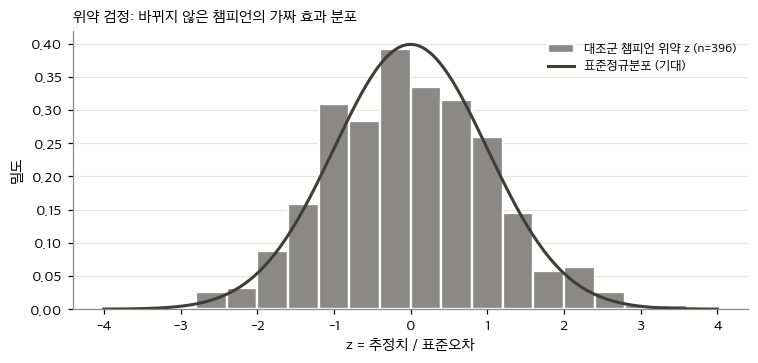

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.arange(-4, 4.01, 0.4)
ax.hist(plac.z, bins=bins, density=True, color=COL["other"], edgecolor="white", linewidth=1.5,
        label=f"대조군 챔피언 위약 z (n={len(plac)})")
x = np.linspace(-4, 4, 200)
ax.plot(x, stats.norm.pdf(x), color=COL["ink"], lw=2, label="표준정규분포 (기대)")
ax.set_xlabel("z = 추정치 / 표준오차")
ax.set_ylabel("밀도")
ax.set_title("위약 검정: 바뀌지 않은 챔피언의 가짜 효과 분포", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8.5)
ax.grid(axis="x", visible=False)
fig.tight_layout()

In [9]:
INFLATE = max(1.0, plac.z.std())
print(f"표준오차 보정 계수: {INFLATE:.2f}")

표준오차 보정 계수: 1.06


오탐률이 기대치(5%)보다 조금 높고 z 분산도 1보다 약간 크다. 표본오차 말고도 챔피언 승률이 패치마다 자연스럽게 출렁이는 몫이 있다는 뜻이다.
아래 그룹 추정에서는 표준오차에 이 계수를 곱해 보수적으로 잡는다. 칼바람과 무관한 변경만 있던 위약 챔피언(쉔, 타릭, 트위스티드 페이트)도
신뢰구간이 모두 0을 포함한다.

## 5. 그룹 단위 효과: 버프·너프는 평균 몇 %p인가

챔피언별 추정치를 역분산 가중으로 묶는다. 챔피언마다 실제 효과 크기가 다를 수 있으므로 랜덤 효과(DerSimonian-Laird)로 추정한다.
`tau`는 챔피언 간 실제 효과의 표준편차 추정치다.

In [10]:
def meta(g):
    se = g.se * INFLATE
    w = 1 / se**2
    fixed = (w * g.est).sum() / w.sum()
    q = (w * (g.est - fixed) ** 2).sum()
    k = len(g)
    tau2 = max(0.0, (q - (k - 1)) / (w.sum() - (w**2).sum() / w.sum())) if k > 1 else 0.0
    wr = 1 / (se**2 + tau2)
    mean, se_m = (wr * g.est).sum() / wr.sum(), wr.sum() ** -0.5
    return pd.Series(dict(k=k, mean=mean, lo=mean - 1.96 * se_m, hi=mean + 1.96 * se_m,
                          p=2 * stats.norm.sf(abs(mean / se_m)), tau=np.sqrt(tau2)))


ORDER = ["buff", "nerf", "adjust", "item", "placebo"]
by_tr = res.groupby(["group", "transition"]).apply(meta, include_groups=False)
overall = res.groupby("group").apply(meta, include_groups=False)
pooled = pd.concat([by_tr, overall.assign(transition="전체").set_index("transition", append=True)])
pooled = pooled.loc[[g for g in ORDER if g in pooled.index.get_level_values(0)]]
pooled.round(3)

k   mean     lo     hi      p    tau
group   transition                                          
buff    16.19→16.20  10.0  1.964 -0.815  4.743  0.166  3.726
        16.20→16.21  11.0  0.222 -1.471  1.915  0.797  1.654
        16.21→16.22   9.0  0.953 -0.499  2.405  0.198  0.000
        전체           30.0  0.988 -0.136  2.112  0.085  2.058
nerf    16.19→16.20   5.0 -0.577 -3.126  1.971  0.657  1.180
        16.20→16.21   9.0 -0.008 -1.622  1.606  0.992  1.173
        16.21→16.22   3.0 -0.061 -2.496  2.373  0.961  0.000
        전체           17.0 -0.196 -1.279  0.887  0.723  0.447
adjust  16.19→16.20   1.0  1.369 -2.681  5.418  0.508  0.000
        16.20→16.21   3.0  0.311 -3.183  3.804  0.862  2.470
        전체            4.0  0.633 -1.916  3.182  0.627  1.795
item    16.19→16.20  13.0 -0.792 -2.144  0.559  0.251  0.000
        16.20→16.21  12.0  1.049 -0.379  2.476  0.150  0.395
        16.21→16.22   2.0 -0.370 -7.573  6.832  0.920  3.537
        전체           27.0  0.016 -0.953  0.985  0.974  0.447
placebo 16.20→16.21   2.0  1.244 -5.314  7.801  0.710  3.743
        16.21→16.22   1.0 -0.070 -4.831  4.692  0.977  0.000
        전체            3.0  0.186 -3.026  3.397  0.910  1.241

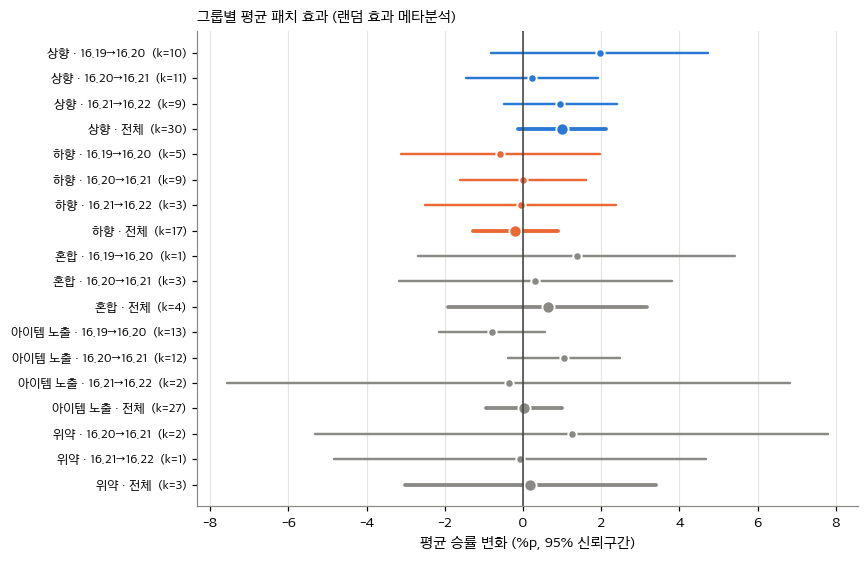

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.2))
LABEL = {"buff": "상향", "nerf": "하향", "adjust": "혼합", "item": "아이템 노출", "placebo": "위약"}
TR_LABELS = [f"{pre}→{post}" for post, pre in TRANSITIONS.items()] + ["전체"]
rows_ = [(g, t) for g in ORDER for t in TR_LABELS if (g, t) in pooled.index]
y = np.arange(len(rows_))[::-1]
for yi, (g, t) in zip(y, rows_):
    r = pooled.loc[(g, t)]
    c = GCOL.get(g, COL["other"])
    ax.plot([r.lo, r.hi], [yi, yi], color=c, lw=2.5 if t == "전체" else 1.6, solid_capstyle="round")
    ax.plot(r["mean"], yi, "o", ms=8 if t == "전체" else 5.5, color=c, mec="white", mew=1.2)
ax.axvline(0, color=COL["ink"], lw=1)
ax.set_yticks(y, [f"{LABEL[g]} · {t}  (k={int(pooled.loc[(g, t)].k)})" for g, t in rows_], fontsize=8.5)
ax.set_xlabel("평균 승률 변화 (%p, 95% 신뢰구간)")
ax.set_title("그룹별 평균 패치 효과 (랜덤 효과 메타분석)", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
fig.tight_layout()

In [12]:
b, nf = overall.loc["buff"], overall.loc["nerf"]
diff = b["mean"] - nf["mean"]
se_diff = np.sqrt(((b.hi - b.lo) / 3.92) ** 2 + ((nf.hi - nf.lo) / 3.92) ** 2)
print(f"상향 평균 {b['mean']:+.2f}%p [{b.lo:+.2f}, {b.hi:+.2f}]  (k={int(b.k)})")
print(f"하향 평균 {nf['mean']:+.2f}%p [{nf.lo:+.2f}, {nf.hi:+.2f}]  (k={int(nf.k)})")
print(f"상향 - 하향 = {diff:+.2f}%p [{diff - 1.96 * se_diff:+.2f}, {diff + 1.96 * se_diff:+.2f}]")

상향 평균 +0.99%p [-0.14, +2.11]  (k=30)
하향 평균 -0.20%p [-1.28, +0.89]  (k=17)
상향 - 하향 = +1.18%p [-0.38, +2.75]


**협곡 기준 버프·너프가 칼바람 승률에 남기는 평균 효과는 1%p 안팎으로 작다.** 하향은 평균적으로 거의 0이다.
협곡 밸런스 수치(라인전, 정글, 오브젝트)가 한 라인 한타 중심인 칼바람에서는 대부분 희석된다는 해석과 맞는다.

다만 평균이 작다고 모든 변경이 작은 건 아니다. 16.19→16.20 상향 그룹은 `tau`(챔피언 간 효과 차이)가 크다. 대부분은 0 근처인데
스웨인 하나가 +12%p로 튀었기 때문이다. **"대부분 희석되지만, 가끔 크게 증폭되는 변경이 있다"**가 데이터가 보여주는 그림이고,
칼바람 전용 보정이 필요한 지점이 바로 그런 경우다.

## 5-1. 칼바람 전용 보정치의 효과

Riot은 협곡 밸런스와 별개로 칼바람 전용 보정치(입히는 피해량, 받는 피해량, 강인함 등)를 조정한다.
이 보정치를 바꿨을 때 승률이 얼마나 움직였는지가, 우리가 제안할 조정 폭의 근거가 된다.

| 패치 | 챔피언 | 변경 |
|---|---|---|
| 26.20 | 벨베스 | 입히는 피해 105→100%, 받는 피해 95→100%, 강인함 20→0% |
| 26.20 | 로크 | 입히는 피해 105→115% |

환산을 위해 "입히는 피해 +1%p"와 "받는 피해 -1%p"를 같은 크기의 상향 1단위로 본다(강인함은 따로 환산하지 않는다).
그러면 벨베스는 -10단위(+강인함 하향), 로크는 +10단위다.

In [13]:
UNITS = {"Belveth": -10, "Locke": +10}   # 보정치 변화량 (상향 +, 하향 -)
am = res[res.group == "aram"].copy()
am["units"] = am.champ.map(UNITS)
am["per_unit"] = am.est / am.units
am["per_unit_se"] = am.se * INFLATE / am.units.abs()
w = 1 / am.per_unit_se**2
elastic = (w * am.per_unit).sum() / w.sum()
elastic_se = w.sum() ** -0.5
print(f"보정치 1%p당 승률 변화: {elastic:+.3f}%p  (95% CI {elastic - 1.96 * elastic_se:+.3f} ~ {elastic + 1.96 * elastic_se:+.3f})")
print(f"→ 보정치 5%p 조정 = 승률 약 {5 * elastic:+.2f}%p")
am[["transition", "name", "n_pre", "n_post", "est", "lo", "hi", "p", "units", "per_unit"]].round(3)

보정치 1%p당 승률 변화: +0.633%p  (95% CI +0.123 ~ +1.144)
→ 보정치 5%p 조정 = 승률 약 +3.17%p


,transition,name,n_pre,n_post,est,lo,hi,p,units,per_unit
4,16.19→16.20,벨베스,334,300,-7.798,-15.572,-0.023,0.049,-10,0.780
15,16.19→16.20,로크,462,473,5.410,-0.757,11.577,0.086,10,0.541


- 벨베스(보정 하향)는 승률이 내려가고, 로크(보정 상향)는 올라갔다. 두 사례 모두 방향이 맞는다.
- 두 사례를 합치면 **보정치 1%p당 승률 약 0.6%p**다. 협곡 밸런스 변경의 평균 효과(1%p 안팎)보다 훨씬 강한 손잡이다.
  칼바람 전용 보정치가 칼바람 밸런스를 맞추는 데 효과적인 도구라는 뜻이다.
- 아직 사례가 2개뿐이고 표본(챔피언당 300~470경기)도 작아 신뢰구간이 넓다. 26.23 칼리스타 보정 하향 등 사례를 더 모아 정밀하게 다듬는다.
- 조정 패치노트에서는 이 환산값으로 조정 폭을 정한다. 예: 승률 55%인 챔피언을 52%로 낮추려면 보정치 약 5%p.

## 6. 개별 추정치 축소 (경험적 베이즈)

챔피언 하나의 추정치는 표준오차가 2~3%p라 우연한 출렁임이 크다. 같은 그룹 평균 쪽으로 당겨서 극단값을 걸러낸다.
축소 정도는 `B = tau² / (tau² + se²)`이며, 표본이 적을수록(se가 클수록) 그룹 평균에 더 가까워진다.

In [14]:
def shrink(g):
    m = meta(g)
    se = g.se * INFLATE
    B = m.tau**2 / (m.tau**2 + se**2)
    post_mean = m["mean"] + B * (g.est - m["mean"])
    post_sd = np.sqrt(B * se**2 + (1 - B) ** 2 * ((m.hi - m.lo) / 3.92) ** 2)
    return g.assign(shrunk=post_mean, s_lo=post_mean - 1.96 * post_sd, s_hi=post_mean + 1.96 * post_sd, B=B)


eb = (res[res.group.isin(["buff", "nerf", "adjust", "item"])]
      .groupby("group", group_keys=False)[res.columns.tolist()].apply(shrink))
eb["shift"] = (eb.shrunk - eb.est).abs()
eb.sort_values("shrunk")[["transition", "name", "group", "n_pre", "n_post", "est", "shrunk", "s_lo", "s_hi", "B"]].round(2)

,transition,name,group,n_pre,n_post,est,shrunk,s_lo,s_hi,B
31,16.20→16.21,아지르,buff,659,969,-7.87,-2.32,-5.59,0.95,0.37
43,16.20→16.21,오공,adjust,800,1057,-2.76,-0.53,-3.84,2.78,0.34
29,16.19→16.20,유나라,nerf,922,1243,-4.42,-0.35,-1.70,1.00,0.04
37,16.20→16.21,징크스,nerf,2074,2654,-2.18,-0.35,-1.65,0.96,0.08
40,16.20→16.21,리 신,nerf,1186,1474,-1.98,-0.28,-1.62,1.07,0.04
52,16.20→16.21,람머스,nerf,388,406,-4.93,-0.26,-1.64,1.11,0.01
72,16.21→16.22,로크,nerf,717,667,-2.83,-0.26,-1.63,1.11,0.02
65,16.20→16.21,요네,nerf,1053,1670,-1.62,-0.26,-1.60,1.09,0.04
3,16.19→16.20,애쉬,nerf,1912,2074,-0.52,-0.22,-1.54,1.10,0.07
9,16.19→16.20,크산테,nerf,317,365,0.74,-0.18,-1.56,1.19,0.01


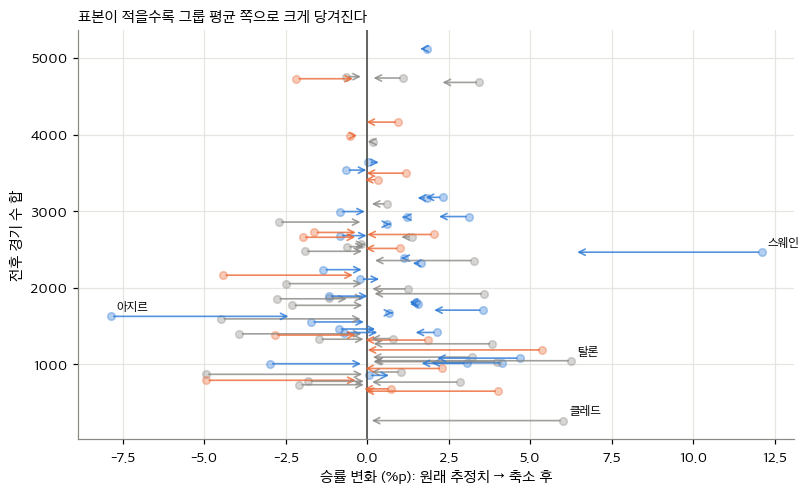

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for r in eb.itertuples():
    c = GCOL.get(r.group, COL["other"])
    ax.annotate("", xy=(r.shrunk, r.n_pre + r.n_post), xytext=(r.est, r.n_pre + r.n_post),
                arrowprops=dict(arrowstyle="->", color=c, lw=1.1, alpha=0.8))
    ax.plot(r.est, r.n_pre + r.n_post, "o", ms=5, color=c, alpha=0.35)
for r in eb.nlargest(4, "shift").itertuples():
    ax.annotate(r.name, (r.est, r.n_pre + r.n_post), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.axvline(0, color=COL["ink"], lw=1)
ax.set_xlabel("승률 변화 (%p): 원래 추정치 → 축소 후")
ax.set_ylabel("전후 경기 수 합")
ax.set_title("표본이 적을수록 그룹 평균 쪽으로 크게 당겨진다", loc="left", fontsize=10)
fig.tight_layout()

그룹 안에서 챔피언 간 실제 효과 차이(`tau`)가 작게 추정되어 축소가 강하다. 하향 그룹은 `tau`가 0으로 추정되어
모든 챔피언이 그룹 평균으로 완전히 모인다. "하향 챔피언끼리 효과 크기가 다르다"는 증거가 아직 없다는 뜻이다. 축소 후에는 대부분 0~1%p 근처로 모인다.
아지르(-7.9 → -2.3%p)처럼 원래 추정치가 극단적이던 경우도 축소 후에는 크게 줄어든다.
반면 **스웨인은 축소 후에도 +6.3%p (95% 구간 3.4~9.3)**로 남는다. 표본이 충분하고 효과가 커서 우연으로 보기 어렵다는 뜻이다.

## 7. 칼바람 조정 후보: 승률 수준

패치 **효과**는 작지만, 챔피언 승률 **수준** 자체는 칼바람에서 크게 갈린다. 칼바람 조정 패치노트는 이 수준을 근거로 쓴다.
챔피언별 승률을 베타-이항 경험적 베이즈로 50% 쪽으로 축소하고, 모든 패치에서 꾸준한지 본다.

In [16]:
lv = parts.groupby(["patch", "champ"]).win.agg(n="size", w="sum").reset_index()

def eb_rate(g):
    p = g.w / g.n
    m = (g.w.sum() / g.n.sum())
    noise = (p * (1 - p) / g.n).mean()
    var_true = max(p.var() - noise, 1e-6)
    k = m * (1 - m) / var_true - 1            # 사전분포 강도 (가상 경기 수)
    a, b = m * k, (1 - m) * k
    return g.assign(raw=p * 100, eb=(g.w + a) / (g.n + a + b) * 100,
                    lo=stats.beta.ppf(0.025, g.w + a, g.n - g.w + b) * 100,
                    hi=stats.beta.ppf(0.975, g.w + a, g.n - g.w + b) * 100, prior_k=k)

lv = lv.groupby("patch", group_keys=False)[lv.columns.tolist()].apply(eb_rate)
print("사전분포 강도(가상 경기 수):", lv.groupby("patch").prior_k.first().round(0).to_dict())
wide = lv.pivot(index="champ", columns="patch", values="eb")
print("패치 간 승률 상관 (축소 후):")
wide.corr().round(2)

사전분포 강도(가상 경기 수): {'16.19': 201.0, '16.20': 258.0, '16.21': 251.0, '16.22': 246.0}
패치 간 승률 상관 (축소 후):


patch,16.19,16.20,16.21,16.22
patch,,,,
16.19,1.00,0.70,0.69,0.65
16.20,0.70,1.00,0.75,0.80
16.21,0.69,0.75,1.00,0.74
16.22,0.65,0.80,0.74,1.00


패치 사이 승률 상관이 높다면 승률 수준은 우연이 아니라 챔피언 고유의 칼바람 적합도다. 이것이 칼바람 전용 보정의 근거가 된다.

스웨인은 16.19에 50%였다가 26.20 상향 뒤 62~65%가 되어서, 아래 "모든 패치에서 꾸준히 강한" 기준에는 걸리지 않는다.
하지만 위 3절에서 본 것처럼 **현재 가장 강한 챔피언**이고, 원인이 된 패치까지 특정되므로 조정 후보 1순위로 따로 다룬다.
또한 16.22에서 4개 패치 내내 강했던 칼리스타는 실제로 26.23에서 Riot이 칼바람 보정치를 하향했다(입히는 피해 110→105%, 받는 피해 90→100%).
이 방법이 실제 조정 대상을 찾아낸다는 근거다.

In [17]:
last = max(patches)
cur = lv[lv.patch == last].set_index("champ")
cons = wide.dropna()
cur = cur.join(cons.add_prefix("eb_"), how="inner")
cur["min_all"] = cons.min(axis=1)
cur["max_all"] = cons.max(axis=1)
cur["name"] = cur.index.map(lambda c: ko.get(c, c))
strong = cur[(cur.lo > 50) & (cur.min_all > 51)].sort_values("eb", ascending=False)
weak = cur[(cur.hi < 50) & (cur.max_all < 49)].sort_values("eb")
cols = ["n", "raw", "eb", "lo", "hi"] + [f"eb_{p}" for p in patches]
print(f"{last} 기준, {len(patches)}개 패치 모두 51% 초과 + 신뢰구간 하한 50% 초과: {len(strong)}종")
strong[cols].round(1)

16.22 기준, 4개 패치 모두 51% 초과 + 신뢰구간 하한 50% 초과: 12종


,n,raw,eb,lo,hi,eb_16.19,eb_16.20,eb_16.21,eb_16.22
champ,,,,,,,,,
Kalista,1041,59.0,57.3,54.6,60.0,56.8,55.7,53.9,57.3
Viktor,1535,56.3,55.4,53.1,57.7,54.5,51.1,52.7,55.4
Tryndamere,586,56.5,54.6,51.2,57.9,55.8,53.9,52.5,54.6
Leona,1000,55.3,54.3,51.5,57.0,55.2,53.0,52.3,54.3
Lux,2510,54.3,53.9,52.1,55.8,52.0,53.4,52.8,53.9
Hwei,1161,54.3,53.5,50.9,56.1,55.2,52.7,54.8,53.5
Yasuo,1254,54.1,53.5,50.9,56.0,53.7,53.1,52.6,53.5
FiddleSticks,1400,54.0,53.4,51.0,55.8,53.3,52.1,52.9,53.4
Velkoz,2163,53.3,52.9,50.9,54.9,52.6,54.7,54.9,52.9


In [18]:
print(f"{last} 기준, {len(patches)}개 패치 모두 49% 미만 + 신뢰구간 상한 50% 미만: {len(weak)}종")
weak[cols].round(1)

16.22 기준, 4개 패치 모두 49% 미만 + 신뢰구간 상한 50% 미만: 19종


,n,raw,eb,lo,hi,eb_16.19,eb_16.20,eb_16.21,eb_16.22
champ,,,,,,,,,
Akali,1028,39.2,41.3,38.6,44.0,43.6,40.8,43.2,41.3
Locke,667,41.1,43.5,40.3,46.7,38.4,42.7,45.5,43.5
LeeSin,1273,42.5,43.7,41.2,46.2,43.0,47.4,45.5,43.7
Khazix,554,42.1,44.5,41.1,48.0,43.7,44.6,46.2,44.5
Leblanc,1463,43.9,44.8,42.4,47.1,46.0,44.9,46.4,44.8
Kennen,1185,43.7,44.8,42.2,47.4,48.1,47.4,46.7,44.8
Zed,1142,43.9,45.0,42.3,47.6,47.6,46.3,48.6,45.0
Qiyana,590,42.9,45.0,41.6,48.4,45.9,46.9,47.8,45.0
Cassiopeia,850,43.5,45.0,42.0,47.9,43.9,45.0,44.4,45.0


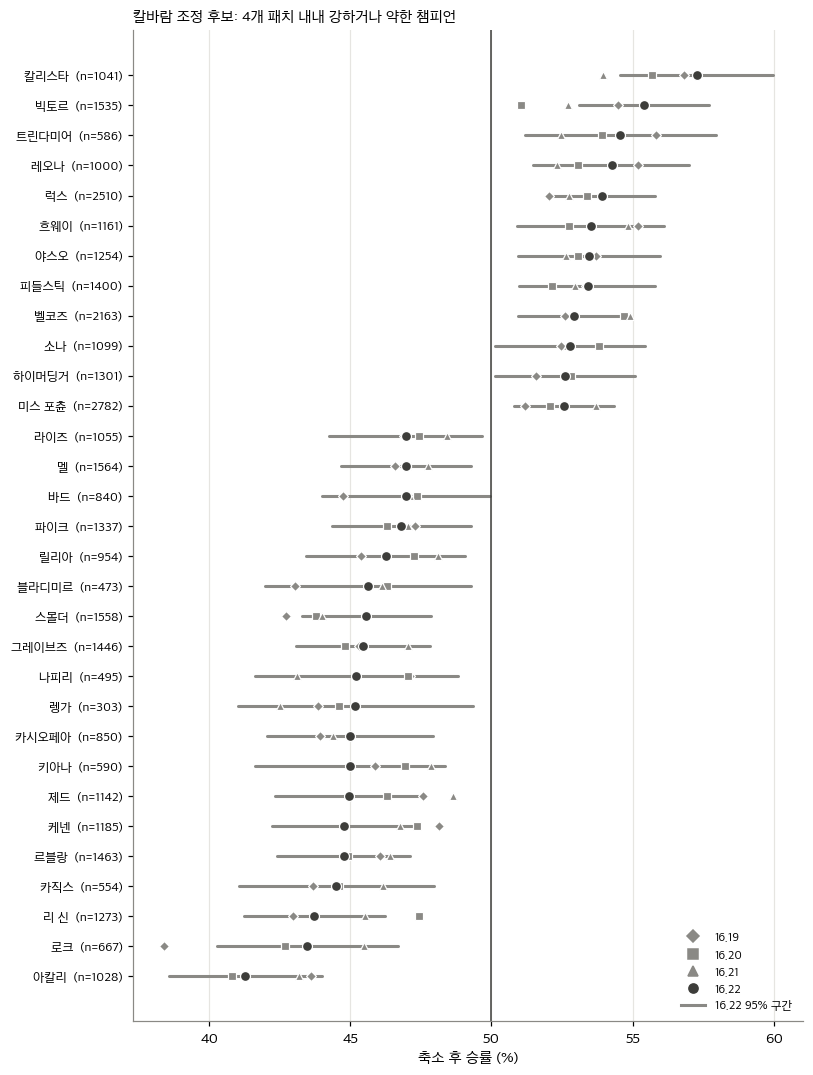

In [19]:
MARKS = ["D", "s", "^", "o"][-len(patches):]

def level_plot(df, title):
    df = df.sort_values("eb")
    fig, ax = plt.subplots(figsize=(7.5, 0.28 * len(df) + 1.2))
    y = np.arange(len(df))
    for yi, (c, r) in zip(y, df.iterrows()):
        ax.plot([r.lo, r.hi], [yi, yi], color=COL["other"], lw=2, solid_capstyle="round")
        for p_, mk in zip(patches, MARKS):
            ax.plot(r[f"eb_{p_}"], yi, mk, ms=5 if p_ != last else 6.5,
                    color=COL["ink"] if p_ == last else COL["other"], mec="white", mew=0.8)
    ax.axvline(50, color=COL["ink"], lw=1)
    ax.set_yticks(y, [f"{r['name']}  (n={int(r.n)})" for _, r in df.iterrows()], fontsize=8.5)
    ax.set_xlabel("축소 후 승률 (%)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
    handles = [plt.Line2D([], [], marker=mk, ls="", color=COL["ink"] if p_ == last else COL["other"], label=p_)
               for p_, mk in zip(patches, MARKS)]
    handles.append(plt.Line2D([], [], color=COL["other"], lw=2, label=f"{last} 95% 구간"))
    ax.legend(handles=handles, frameon=False, fontsize=8, loc="lower right")
    fig.tight_layout()

level_plot(pd.concat([strong, weak]), f"칼바람 조정 후보: {len(patches)}개 패치 내내 강하거나 약한 챔피언")

## 8. 정리

| 질문 | 답 |
|---|---|
| 챔피언별 패치 효과 | 대부분 신뢰구간이 0을 포함. 예외는 **스웨인(26.20 상향, +12%p)**으로, 다중비교·축소 후에도 남는다 |
| 방법 검증 | 위약 오탐률 6.3% (기대 5%) → 표준오차를 소폭 보정. 위약 챔피언 3종은 모두 0 근처 |
| 그룹 평균 효과 | 협곡 버프·너프가 칼바람 승률에 남기는 평균 효과는 1%p 안팎. 대부분 희석되지만 가끔 크게 증폭된다 |
| 칼바람 보정치 효과 | 보정치 1%p당 승률 약 0.6%p (사례 2개, 구간 넓음). 협곡 변경보다 훨씬 강한 손잡이 |
| 칼바람 조정 근거 | 승률 **수준**이 크고 패치 간 일관적이다. 4개 패치 내내 강했던 칼리스타는 실제로 26.23에서 보정 하향됨 |

**한계**
- 비교 구간이 3개, 보정치 사례가 2개뿐이다. 패치를 더 모으면 신뢰구간이 좁아진다.
- 스노볼 표본이라 칼바람을 자주 하는 플레이어가 과대표집된다. 플레이어당 3경기로 제한해 완화했다.
- 칼바람은 리롤·교환이 있어 챔피언 배정이 완전히 무작위는 아니다.
- 팀 조합, 플레이어 숙련도는 아직 통제하지 않았다.